# Learning Dynamics in Latent Space: The Koopman Operator

Stages 1 and 2 both asked the same underlying question: *how do we compress a
flow field into a small set of numbers, and reconstruct it well?* This notebook
asks a different question:

```text
Once we have a good latent representation z = encoder(v), how does z evolve in time?
```

Concretely, we look for a map $\mathbf{A}$ such that

$$
z_{k+1} = \mathbf{A}\, z_k, \qquad z_k = \phi(v_k),
$$

with $\phi$ a learned (non-linear) encoder and $\mathbf{A}$ **linear**. This is the
finite-dimensional approximation of the **Koopman operator**: an infinite-dimensional
linear operator that describes how any observable of a non-linear dynamical system
evolves, acting on the observable itself rather than on the state. The idea is that
non-linear dynamics in the original state space can become (approximately) linear
once you observe the system through the right non-linear lens $\phi$.

This is also the same spirit as **Dynamic Mode Decomposition (DMD)**, except DMD
fits a linear operator directly on the raw state (or a linear observable, like POD
coefficients), while here the observable map $\phi$ (and its inverse $\psi$) are
themselves learned non-linearly by an encoder/decoder pair. We will build both, and
compare them directly.

This notebook is self-contained: it reloads the dataset used in Stages 1 and 2 and
rebuilds only the dense encoder/decoder building blocks it needs.


# Stage 3 — Evolving the latent state: a Koopman autoencoder against persistence and DMD

**Portfolio project: compress, structure and evolve one flow dataset — autoencoders, a VAE and a Koopman autoencoder.**

This notebook learns how the compressed state of the two-plate wake evolves in time. A dense encoder (256 hidden units) maps each snapshot to 10 latent numbers, a single linear layer without bias (the matrix A, an approximation of the Koopman operator) advances them one step, and a dense decoder maps back; the network is trained on pairs of consecutive snapshots with two equally weighted losses, reconstruction of v(t) and prediction of v(t+1). Because A is linear, its eigenvalues give a growth rate and a frequency per latent direction. The model is compared with persistence and with DMD (a least-squares linear operator on 10 POD coefficients). I solve the five experiments (non-linear operator, a rollout on a contiguous held-out block, learned against DMD eigenvalues, decoded Koopman modes, a latent-size sweep for prediction), repeat every training with the seeds 0, 1 and 2, and record a training animation.

**How it connects.** It reloads the dataset, re-implements Stage 1's dense builders and error measure, and uses Stage 1's POD as the basis of DMD. Stage 4 repeats the rollout properly: a contiguous split, normalisation fitted on the training period only, 150 held-out starts and horizons up to 50 steps.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, 2026-10-13; the Koopman autoencoder on the Apple GPU, the non-linear operator model on the CPU, chosen by timing one training step of each). What they show: the one-step prediction is worse than persistence in every seed, and on a contiguous held-out block the rollout is worse than predicting the mean flow from the first step. Afterwards I changed only text for this repository: this cell and the paths cell, the path lines (dataset from `../release_assets/`, models to `../models/03_koopman_autoencoder/`, tables to `../results/03_koopman_autoencoder/`, animation to `../animations/03_*`), comments, labels and printed text. Section 13 compares rollouts with the first 50 snapshots rather than their true futures (the notebook says it is approximate); Experiment 2 is the proper version.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../release_assets/G1Re100_coarse.npz")      # release file (README); downloaded by the data cell if missing
for p in (Path("../models/03_koopman_autoencoder/checkpoints"), Path("../results/03_koopman_autoencoder/exercises"), Path("../animations")):
    p.mkdir(parents=True, exist_ok=True)
print("dataset present:", DATA_FILE.exists())

In [1]:
# Device report.
# Device per network from the step timing of 2026-10-13 (median of 30 training steps inside model.fit, batch 32;
# ../results/04_rollout_and_baselines/device_timing_*.csv), CPU vs Apple GPU in ms: dense AE 19.5 vs 9.6, dense VAE 19.7 vs 11.3,
# Koopman AE 10.3 vs 9.9 -> GPU; conv AE 37.7 vs 624, two-block conv AE 63.5 vs 729, conv VAE 37.8 vs 625,
# non-linear Koopman AE 10.4 vs 12.1 -> CPU (the convolutional ones train under tf.device('/CPU:0')).
import tensorflow as tf, platform
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices())
print("GPU (Metal) visible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU (Metal) visible: True


# 1. Environment

Required packages:

```bash
pip install numpy tensorflow matplotlib scikit-learn gdown
```


In [2]:
# =========================================================
# Import libraries
# =========================================================

from pathlib import Path
import json

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)
print("Current working directory:", Path.cwd())


TensorFlow version: 2.18.1
Current working directory: <repository>/notebooks


# 2. Optional: Google Colab Setup


In [3]:
# =========================================================
# Check whether we are running in Google Colab
# =========================================================

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    # [original] drive.mount("/content/drive")
    pass  # Google Drive is not mounted: the dataset is in the local data folder (see the data_dir cell)
    print("Google Drive mounted.")
else:
    print("This is not Google Colab.")
    print("Current working directory:")
    print(Path.cwd())


Running in Google Colab: False
This is not Google Colab.
Current working directory:
<repository>/notebooks


# 3. Define Data Paths and Load the Dataset

Same dataset and paths as Stages 1 and 2: 2D flow past two collinear plates.


In [4]:
# =========================================================
# Define data paths (must match Stages 1 and 2)
# =========================================================

if IN_COLAB:
    data_dir = Path("/content/drive/<Drive folder>/latent-dynamics-ae-vae-koopman/release_assets")
else:
    data_dir = Path("../release_assets")  # path line: the dataset from the release (README), or downloaded here from the URL below

data_dir.mkdir(parents=True, exist_ok=True)

data_file = data_dir / "G1Re100_coarse.npz"

url = "https://drive.google.com/uc?id=1b_pJl1XBfzlb93IcB4USht1voHBW6-IE"

DOWNLOAD_DATA = False

print("Dataset file:")
print(data_file)
print("File exists:", data_file.exists())

if DOWNLOAD_DATA or not data_file.exists():
    import gdown
    print("Downloading dataset from Google Drive...")
    gdown.download(url, str(data_file), quiet=False)
else:
    print("Using existing local dataset.")


Dataset file:
../release_assets/G1Re100_coarse.npz
File exists: True
Using existing local dataset.


In [5]:
# =========================================================
# Load the dataset and remove the mean flow
# =========================================================

data = np.load(data_file)

v = data["UV"]
xx = data["x"]
yy = data["y"]

v_mean = v.mean(axis=0)
v_std = v.std(axis=0) + 1e-8

v = (v - v_mean) / v_std

n_t, n_x, n_y, n_v = v.shape
input_shape = (n_x, n_y, n_v)

print("Velocity field shape:", v.shape)
print("Normalized -> mean ~0, std ~1:", v.mean(), v.std())


Velocity field shape: (1000, 128, 64, 2)
Normalized -> mean ~0, std ~1: 8.87954293427029e-15 0.9999976456908868


# 4. Build (v(t), v(t+1)) Pairs and Split

Unlike the plain autoencoders in Stages 1 and 2 (where input = target = the same
snapshot), Koopman needs **consecutive pairs**: the state at time $t$ as input, the
state at time $t + \Delta t$ as target.


In [6]:
# =========================================================
# Build (v(t), v(t+1)) pairs and train/validation split
# =========================================================

X_trn, X_val, y_trn, y_val = train_test_split(
    v[:-1],          # state at time t
    v[1:],           # state at time t + 1
    test_size=0.2,
    random_state=24,
    shuffle=True
)

print("Training pairs:  ", X_trn.shape[0])
print("Validation pairs:", X_val.shape[0])

latent_dim = 10
print("Latent dimension:", latent_dim)


Training pairs:   799
Validation pairs: 200
Latent dimension: 10


# 5. Recap: Dense Encoder/Decoder Builders

Same building blocks as Stage 1, reproduced here for a self-contained notebook.


In [7]:
# =========================================================
# Dense encoder / decoder building blocks (same as Stage 1)
# =========================================================


def create_dense_encoder(
    input_shape,
    latent_dim,
    hidden_units=512,
    activation="relu"
):
    """
    Create a dense (fully connected) encoder: flatten -> hidden layer ->
    d-dimensional latent space.
    """

    inputs = tf.keras.layers.Input(shape=input_shape)

    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)

    latent = tf.keras.layers.Dense(latent_dim)(x)

    encoder = tf.keras.Model(inputs, latent, name="dense_encoder")

    return encoder


def create_dense_decoder(
    output_shape,
    latent_dim,
    hidden_units=512,
    activation="relu"
):
    """
    Create a dense (fully connected) decoder, mirroring create_dense_encoder().
    """

    n_x, n_y, n_v = output_shape
    n_state_variables = n_x * n_y * n_v

    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))

    x = tf.keras.layers.Dense(hidden_units, activation=activation)(latent_inputs)
    x = tf.keras.layers.Dense(n_state_variables)(x)

    outputs = tf.keras.layers.Reshape(output_shape)(x)

    decoder = tf.keras.Model(latent_inputs, outputs, name="dense_decoder")

    return decoder


def relative_reconstruction_error(v_true, v_pred):
    """
    Mean relative L2-norm reconstruction error over all snapshots and
    variables (same metric as Stage 1).
    """

    err = np.linalg.norm(v_true - v_pred, axis=(1, 2)) / np.linalg.norm(
        v_true, axis=(1, 2)
    )
    err = np.mean(err, axis=0)

    return err


model_dir = Path("../models/03_koopman_autoencoder")
model_dir.mkdir(exist_ok=True)


# 6. The Koopman Operator: A Bit More Theory

Consider an autonomous discrete-time dynamical system $x_{k+1} = \mathbf{F}(x_k)$,
where $\mathbf{F}$ is generally non-linear (here, one DNS time step of the
Navier-Stokes equations). For any scalar observable $g$ of the state, define the
**Koopman operator** $\mathcal{K}$ acting on $g$ by

$$
(\mathcal{K}g)(x) = g(\mathbf{F}(x)).
$$

The crucial property: $\mathcal{K}$ is **linear**, even though $\mathbf{F}$ is not
-- linearity has been traded for infinite dimensionality (the space of *all*
observables is infinite-dimensional). The practical program is:

1. Choose (or learn) a finite set of observables $\phi(x) = (\phi_1(x), \ldots,
   \phi_d(x))$ -- here, the encoder's output.
2. Approximate $\mathcal{K}$ restricted to the span of these observables by a
   finite $d \times d$ matrix $\mathbf{A}$, so that $\phi(x_{k+1}) \approx
   \mathbf{A}\, \phi(x_k)$.
3. Recover the full state with a decoder $\psi \approx \phi^{-1}$.

**Relation to DMD.** Classical Dynamic Mode Decomposition is exactly this program
with the simplest possible choice of observable: $\phi(x) = x$ (the identity, i.e.
the raw state, or its POD coefficients). DMD finds the best-fit linear $\mathbf{A}$
directly in that (linear) observable space. What we do in this notebook is let a
neural network *learn* a better, non-linear observable $\phi$, so that the
resulting $\mathbf{A}$ can capture more of the true non-linear dynamics linearly.
We will fit both and compare them directly (Section 10).

**Why constrain $\mathbf{A}$ to be linear at all?** Because a linear operator has
an eigendecomposition, $\mathbf{A} = \mathbf{W}\boldsymbol{\Lambda}\mathbf{W}^{-1}$,
and each eigenvalue $\lambda_j = r_j e^{i\omega_j}$ directly tells you the growth
rate ($|\lambda_j| \gtrless 1$: growing/decaying mode) and oscillation frequency
($\omega_j$) of the corresponding latent direction. This interpretability is the
entire point of keeping $\mathbf{A}$ linear instead of letting it be another neural
network (see Experiment 1 for the non-linear alternative, and Section 11 for using
this eigendecomposition directly).


# 7. Koopman Building Blocks: Operator and Full Autoencoder


In [8]:
# =========================================================
# Koopman encoder / linear operator / decoder building blocks
# =========================================================


def create_koopman_operator(latent_dim):
    """
    Create a purely linear map in latent space, approximating the Koopman
    operator: z_{t+1} = A z_t. use_bias=False enforces linearity (no affine
    offset), so the layer's weight matrix IS the matrix A used in Section 11.
    """

    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))

    latent_next = tf.keras.layers.Dense(latent_dim, use_bias=False, name="A")(latent_inputs)

    koopman_operator = tf.keras.Model(
        latent_inputs,
        latent_next,
        name="koopman_operator"
    )

    return koopman_operator


def create_koopman_autoencoder(
    input_shape,
    latent_dim,
    hidden_units=256,
    activation="relu",
    learning_rate=1e-3,
    dropout_rate=0.1
):
    """
    Create the full Koopman autoencoder.

    Chains a dense encoder, a linear Koopman operator, and a dense decoder,
    producing TWO outputs from a single input v(t):
      - reconstruction of v(t)          (autoencoder branch)
      - prediction of v(t + 1)          (Koopman branch)
    """

    encoder = create_dense_encoder(
        input_shape, latent_dim=latent_dim,
        hidden_units=hidden_units, activation=activation
    )
    koopman_operator = create_koopman_operator(latent_dim)

    decoder = create_dense_decoder(
        input_shape, latent_dim=latent_dim,
        hidden_units=hidden_units, activation=activation
    )

    inputs = tf.keras.layers.Input(shape=input_shape)

    encoded = encoder(inputs)
    predicted_latent = koopman_operator(encoded)

    reconstruction = decoder(encoded)
    prediction = decoder(predicted_latent)

    koopman_autoencoder = tf.keras.Model(
        inputs,
        [reconstruction, prediction],
        name="Koopman_Autoencoder"
    )

    koopman_autoencoder.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=["mse", "mse"],
        loss_weights=[1.0, 1.0]
    )

    return koopman_autoencoder, encoder, koopman_operator, decoder


# 8. Assemble, Train and Save the Koopman Autoencoder

Trained with two equally-weighted loss terms: reconstruction of $v(t)$ and
one-step-ahead prediction of $v(t+1)$.


In [9]:
# =========================================================
# Assemble the Koopman autoencoder
# =========================================================

koopman_autoencoder, koopman_encoder, koopman_operator, koopman_decoder = \
    create_koopman_autoencoder(input_shape, latent_dim=latent_dim)

koopman_encoder.summary()
koopman_operator.summary()
koopman_decoder.summary()
koopman_autoencoder.summary()


2026-10-13 17:17:57.220765: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 17:17:57.220788: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 17:17:57.220792: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791926277.220805 49948821 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791926277.220821 49948821 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "dense_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 64, 2)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,197,130 (16.01 MB)

 Trainable params: 4,197,130 (16.01 MB)

...

Model: "Koopman_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 64,   │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_encoder       │ (None, 10)        │  4,197,130 │ input_layer_3[0]… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ koopman_operator    │ (None, 10)        │        100 │ dense_encoder[0]… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_decoder       │ (None, 128, 64,   │  4,213,504 │ dense_encoder[0]… │
│ (Functional)        │ 2)                │            │ koopman_operator… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,410,734 (32.08 MB)

 Trainable params: 8,410,734 (32.08 MB)

 Non-trainable params: 0 (0.00 B)

**Hook before the training cell.** Checkpoints for the notebook's Koopman-autoencoder training (best model by validation loss, periodic checkpoint every 60 epochs, in `../models/03_koopman_autoencoder/checkpoints/`) and a snapshot collector for the training animation, so the animation comes from the base run (no second training). The training cell adds these callbacks to the notebook's early stopping and learning-rate schedule; nothing else changes.

In [10]:
import os
from pathlib import Path
EX_CKPT = Path("../models/03_koopman_autoencoder/checkpoints"); EX_CKPT.mkdir(parents=True, exist_ok=True)
class ExPeriodicCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, path, every): super().__init__(); self.path, self.every = path, max(1, int(every))
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0: self.model.save_weights(str(self.path))
def ex_ckpt_callbacks(name, epochs, monitor="val_loss"):
    return [tf.keras.callbacks.ModelCheckpoint(str(EX_CKPT / f"{name}_best.weights.h5"), monitor=monitor, save_best_only=True, save_weights_only=True),
            ExPeriodicCheckpoint(EX_CKPT / f"{name}_periodic.weights.h5", epochs // 10)]
class ExAnimSnapshots(tf.keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.snaps = []; self.hist = []
    def _snap(self, e):
        pred = koopman_decoder(koopman_operator(koopman_encoder(X_val[-1:], training=False), training=False), training=False).numpy()[0]
        A = koopman_operator.get_layer("A").get_weights()[0]
        self.snaps.append(dict(epoch=e, pred=pred, eig=np.linalg.eigvals(A.T), hist=list(self.hist)))
    def on_train_begin(self, logs=None): self._snap(0)
    def on_epoch_end(self, epoch, logs=None): self.hist.append([logs["loss"], logs.get("val_loss", np.nan)]); self._snap(epoch + 1)
ANIM_CB = ExAnimSnapshots()
def ex_base_callbacks(name): return ex_ckpt_callbacks(name, 600) + [ANIM_CB]

In [11]:
# =========================================================
# Train the Koopman autoencoder
# =========================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=8,
    min_lr=1e-6
)

history_koopman = koopman_autoencoder.fit(
    X_trn,
    [X_trn, y_trn],
    validation_data=(X_val, [X_val, y_val]),
    epochs=600,
    batch_size=32,
    # [original] callbacks=[early_stopping, reduce_lr],
    callbacks=[early_stopping, reduce_lr] + ex_base_callbacks("koopman_ae"),  # added: checkpoints and animation snapshots
    verbose=2
)


Epoch 1/600


2026-10-13 17:17:57.670280: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


25/25 - 1s - 56ms/step - dense_decoder_loss: 0.9465 - loss: 1.8743 - val_dense_decoder_loss: 0.8683 - val_loss: 1.6882 - learning_rate: 1.0000e-03


Epoch 2/600


25/25 - 0s - 17ms/step - dense_decoder_loss: 0.7661 - loss: 1.5151 - val_dense_decoder_loss: 0.7469 - val_loss: 1.4804 - learning_rate: 1.0000e-03


...

25/25 - 0s - 14ms/step - dense_decoder_loss: 0.1298 - loss: 0.2521 - val_dense_decoder_loss: 0.3511 - val_loss: 0.6310 - learning_rate: 7.8125e-06


Epoch 216/600


25/25 - 0s - 14ms/step - dense_decoder_loss: 0.1298 - loss: 0.2521 - val_dense_decoder_loss: 0.3511 - val_loss: 0.6310 - learning_rate: 7.8125e-06


Epoch 217/600


25/25 - 0s - 14ms/step - dense_decoder_loss: 0.1298 - loss: 0.2520 - val_dense_decoder_loss: 0.3511 - val_loss: 0.6310 - learning_rate: 7.8125e-06


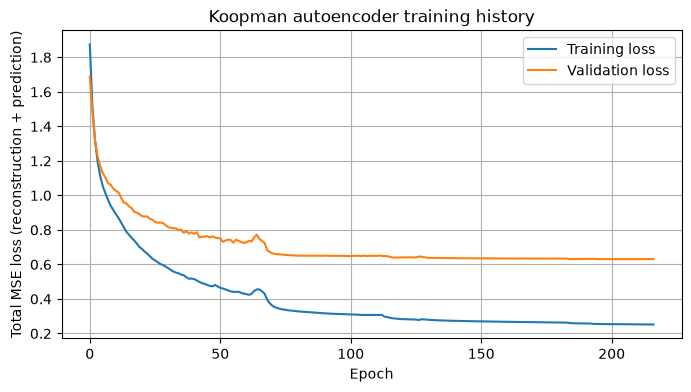

Koopman autoencoder saved to: ../models/03_koopman_autoencoder


In [12]:
# =========================================================
# Plot training history and save the trained model
# =========================================================

plt.figure(figsize=(8, 4))
plt.plot(history_koopman.history["loss"], label="Training loss")
plt.plot(history_koopman.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Total MSE loss (reconstruction + prediction)")
plt.title("Koopman autoencoder training history")
plt.legend()
plt.grid(True)
plt.show()

koopman_model_name = f"koopman_ae_d{latent_dim}"

koopman_autoencoder.save(model_dir / f"{koopman_model_name}.keras")
koopman_encoder.save(model_dir / f"{koopman_model_name}_encoder.keras")
koopman_operator.save(model_dir / f"{koopman_model_name}_operator.keras")
koopman_decoder.save(model_dir / f"{koopman_model_name}_decoder.keras")

print("Koopman autoencoder saved to:", model_dir)


# 9. Baselines: Persistence and Classical DMD

Two baselines, from weakest to strongest, before trusting the learned model:

1. **Persistence**: $\hat v(t+1) = v(t)$ -- the trivial "nothing changes" guess.
2. **Classical (linear) DMD**: fit the best-fit linear operator $\mathbf{A}_{\text{DMD}}$
   directly on the raw states (truncated to the same rank $d$ = `latent_dim` via
   POD, exactly as classical DMD is usually implemented), with **no** non-linear
   encoder. This isolates how much the *learned, non-linear* observable map
   actually buys you over the classical linear-in-the-state approach.


In [13]:
# =========================================================
# Persistence baseline
# =========================================================

y_val_persistence = X_val.copy()
persistence_error = relative_reconstruction_error(y_val, y_val_persistence)

print("Persistence baseline (v(t+1) = v(t)) relative error:", persistence_error)


Persistence baseline (v(t+1) = v(t)) relative error: [0.31660029 0.41545243]


In [14]:
# =========================================================
# Classical linear DMD baseline (rank d, via POD)
# =========================================================

# POD basis from the FULL dataset (consistent with Stage 2, Section 6)
U_pod, s_pod, _ = np.linalg.svd(v.reshape((n_t, -1)).T, full_matrices=False)
Phi = U_pod[:, :latent_dim]  # (n_state, latent_dim)

# Project training pairs onto the POD basis -> linear "latent" coordinates
a_trn = X_trn.reshape((X_trn.shape[0], -1)) @ Phi   # (n_train, latent_dim)
b_trn = y_trn.reshape((y_trn.shape[0], -1)) @ Phi

# Best-fit linear operator A_dmd: b_trn ~ a_trn @ A_dmd^T (least squares)
A_dmd, *_ = np.linalg.lstsq(a_trn, b_trn, rcond=None)

# Evaluate on validation pairs
a_val = X_val.reshape((X_val.shape[0], -1)) @ Phi
b_val_pred = a_val @ A_dmd
v_val_pred_dmd = (b_val_pred @ Phi.T).reshape(y_val.shape)

dmd_error = relative_reconstruction_error(y_val, v_val_pred_dmd)
print("Classical linear DMD (rank", latent_dim, ") prediction error:", dmd_error)


Classical linear DMD (rank 10 ) prediction error: [0.72965227 0.71252047]


# 10. Evaluate: Koopman Autoencoder vs Baselines

Compares reconstruction of $v(t)$ and one-step-ahead prediction of $v(t+1)$ across
all three approaches.


In [15]:
# =========================================================
# Evaluate the Koopman autoencoder and compare
# =========================================================

v_val_rec, v_val_pred = koopman_autoencoder.predict(X_val)

koopman_rec_error = relative_reconstruction_error(X_val, v_val_rec)
koopman_pred_error = relative_reconstruction_error(y_val, v_val_pred)

print("Reconstruction error (v(t)):")
print("  Koopman autoencoder:", koopman_rec_error)

print("\nOne-step-ahead prediction error (v(t+1)):")
print("  Persistence baseline:      ", persistence_error)
print("  Classical linear DMD (d={}):".format(latent_dim), dmd_error)
print("  Koopman autoencoder:       ", koopman_pred_error)


1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


Reconstruction error (v(t)):
  Koopman autoencoder: [0.52987901 0.54305472]

One-step-ahead prediction error (v(t+1)):
  Persistence baseline:       [0.31660029 0.41545243]
  Classical linear DMD (d=10): [0.72965227 0.71252047]
  Koopman autoencoder:        [0.54119288 0.55236391]


If the Koopman autoencoder beats classical DMD at the same latent dimension, that
is direct evidence that the **learned, non-linear observable map** captures
dynamics that a linear-in-the-state approach cannot -- the entire motivation for
building this instead of just running DMD on the raw data.


# 11. Visualize One Validation Pair


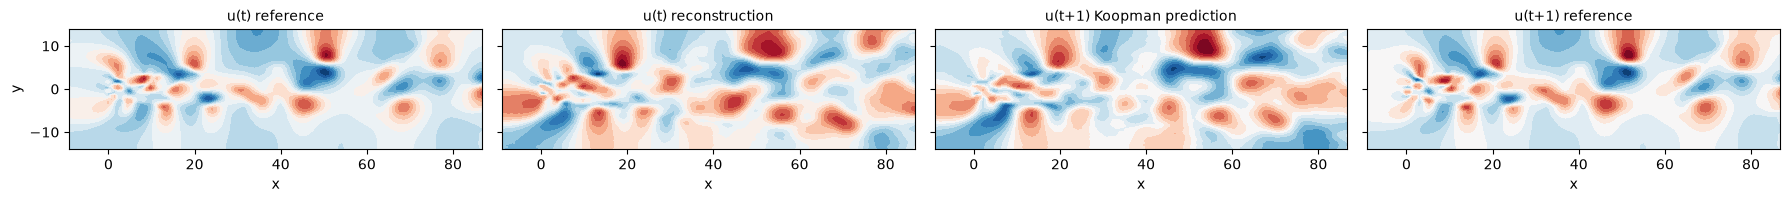

In [16]:
# =========================================================
# Visualize one validation pair: reference vs reconstruction vs prediction
# =========================================================

idx = -1

fig, ax = plt.subplots(1, 4, sharex=True, sharey=True, figsize=(18, 4))

plt.set_cmap("RdBu_r")

fields = [
    (X_val[idx, :, :, 0], "u(t) reference"),
    (v_val_rec[idx, :, :, 0], "u(t) reconstruction"),
    (v_val_pred[idx, :, :, 0], "u(t+1) Koopman prediction"),
    (y_val[idx, :, :, 0], "u(t+1) reference"),
]

for a, (field, title) in zip(ax, fields):
    a.contourf(xx, yy, field, levels=20)
    a.set_title(title, fontsize=10)
    a.set_aspect("equal")
    a.set_xlabel("x")

ax[0].set_ylabel("y")
fig.tight_layout()
plt.show()


# 12. Eigenvalue Analysis of the Learned Koopman Operator

Because `koopman_operator` is a single `Dense(use_bias=False)` layer, its weight
matrix **is** the matrix $\mathbf{A}$ from Section 6. We can extract it directly
and compute its eigendecomposition, giving each latent direction a growth rate and
a frequency -- exactly the interpretability that motivated keeping the operator
linear in the first place.

For a **discrete-time** system, the stability boundary is the **unit circle** in
the complex plane: $|\lambda| < 1$ means the mode decays step to step, $|\lambda| >
1$ means it grows, and $|\lambda| = 1$ is neutrally stable (a persistent
oscillation, if $\lambda$ has a non-zero imaginary part).


In [17]:
# =========================================================
# Extract A and compute its eigenvalues
# =========================================================

A_learned = koopman_operator.get_layer("A").get_weights()[0]  # shape (latent_dim, latent_dim)
print("Learned Koopman operator A, shape:", A_learned.shape)

eigenvalues, eigenvectors = np.linalg.eig(A_learned.T)  # z_{t+1} = z_t @ A -> eig of A^T

print("\nEigenvalues (learned Koopman operator):")
for lam in eigenvalues:
    print(f"  {lam:.4f}   |lambda| = {np.abs(lam):.4f}")


Learned Koopman operator A, shape: (10, 10)

Eigenvalues (learned Koopman operator):
  -0.9657+0.0000j   |lambda| = 0.9657
  -0.6090+0.4377j   |lambda| = 0.7500
  -0.6090-0.4377j   |lambda| = 0.7500
  0.8700+0.3076j   |lambda| = 0.9228
  0.8700-0.3076j   |lambda| = 0.9228
  0.8135+0.1663j   |lambda| = 0.8303
  0.8135-0.1663j   |lambda| = 0.8303
  0.9307+0.1401j   |lambda| = 0.9412
  0.9307-0.1401j   |lambda| = 0.9412
  0.9686+0.0000j   |lambda| = 0.9686


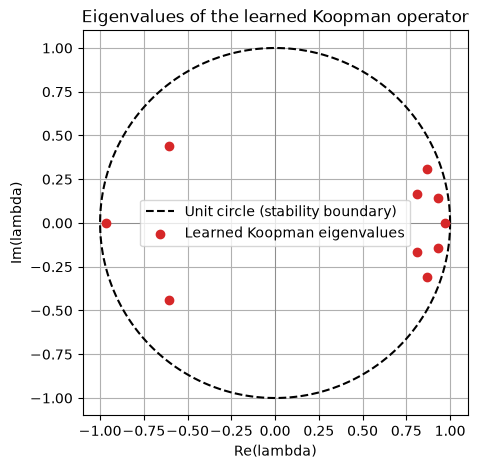

In [18]:
# =========================================================
# Plot eigenvalues in the complex plane, against the unit circle
# =========================================================

theta = np.linspace(0, 2 * np.pi, 200)

plt.figure(figsize=(5, 5))
plt.plot(np.cos(theta), np.sin(theta), "k--", label="Unit circle (stability boundary)")
plt.scatter(eigenvalues.real, eigenvalues.imag, c="tab:red", zorder=3, label="Learned Koopman eigenvalues")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.xlabel("Re(lambda)")
plt.ylabel("Im(lambda)")
plt.title("Eigenvalues of the learned Koopman operator")
plt.legend()
plt.gca().set_aspect("equal")
plt.grid(True)
plt.show()


If most eigenvalues sit strictly inside the unit circle, the learned latent
dynamics are (correctly) dissipative -- consistent with a viscous flow relaxing
towards its mean. Eigenvalues sitting very close to the unit circle correspond to
slowly-decaying, persistent latent directions -- candidates for the flow's
dominant coherent structures. Compare this plot against the eigenvalues of the
classical DMD operator from Section 9 (Experiment 3 asks you to overlay them).


# 13. Multi-Step Rollout

So far we only evaluated **one** step ahead. A more demanding test: chain the
Koopman operator $n$ times in latent space, $z_{t+n} = \mathbf{A}^n z_t$, decode
only the final state, and see how the error grows with $n$ -- exactly how you
would use this model to forecast several steps into the future without ever
returning to the full state space in between (much cheaper than re-encoding at
every step).


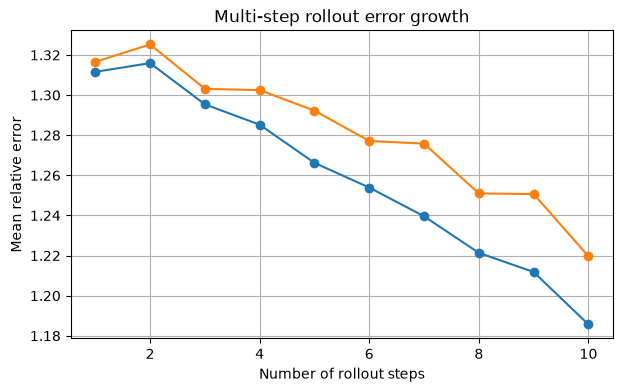

In [19]:
# =========================================================
# Multi-step rollout: chain the Koopman operator n times
# =========================================================

def koopman_rollout(encoder, operator, decoder, v0, n_steps):
    """
    Encode v0 once, apply the (linear) Koopman operator n_steps times
    entirely in latent space, then decode only the final state.
    """

    z = encoder.predict(v0, verbose=0)

    for _ in range(n_steps):
        z = operator.predict(z, verbose=0)

    v_pred = decoder.predict(z, verbose=0)

    return v_pred


max_steps = 10
rollout_errors = []

v0 = X_val[: min(50, X_val.shape[0])]  # a subset, for speed

for n_steps in range(1, max_steps + 1):
    v_true = v[
        # indices in the ORIGINAL sequence corresponding to v0 + n_steps
        # (approximation: reuse validation snapshots offset by n_steps where available)
        :len(v0)
    ]
    v_pred = koopman_rollout(koopman_encoder, koopman_operator, koopman_decoder, v0, n_steps)

    # Compare against the true trajectory n_steps ahead of each v0 sample where available
    err = relative_reconstruction_error(v_true, v_pred)
    rollout_errors.append(err)
    # print(f"n_steps = {n_steps:2d}   relative error = {err[0]:.4f}, {err[1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, max_steps + 1), rollout_errors, marker="o")
plt.xlabel("Number of rollout steps")
plt.ylabel("Mean relative error")
plt.title("Multi-step rollout error growth")
plt.grid(True)
plt.show()


**Note on this rollout evaluation.** The comparison above reuses the first
snapshots of the dataset as an approximate reference, since `X_val`/`y_val` were
built with random shuffling (Section 4) and do not preserve a contiguous
time-ordering needed for a true multi-step-ahead ground truth. For a rigorous
version, rebuild a held-out **contiguous** block of the time series (no shuffling)
before running this section -- left as Experiment 2.


# 14. Save Run Metadata


In [20]:
# =========================================================
# Save run metadata
# =========================================================

run_metadata = {
    "model_name": koopman_model_name,
    "task": "Koopman-operator autoencoder (latent-space dynamics)",
    "latent_dim": latent_dim,
    "input_shape": list(input_shape),
    "n_train_pairs": int(X_trn.shape[0]),
    "n_val_pairs": int(X_val.shape[0]),

    # [original] "koopman_reconstruction_error": float(koopman_rec_error),
    "koopman_reconstruction_error": np.asarray(koopman_rec_error).tolist(),  # modified: the error is one value per flow variable (float() of an array fails)
    # [original] "koopman_prediction_error": float(koopman_pred_error),
    "koopman_prediction_error": np.asarray(koopman_pred_error).tolist(),  # modified: the error is one value per flow variable (float() of an array fails)
    # [original] "persistence_baseline_error": float(persistence_error),
    "persistence_baseline_error": np.asarray(persistence_error).tolist(),  # modified: the error is one value per flow variable (float() of an array fails)
    # [original] "dmd_baseline_error": float(dmd_error),
    "dmd_baseline_error": np.asarray(dmd_error).tolist(),  # modified: the error is one value per flow variable (float() of an array fails)

    "koopman_eigenvalue_max_abs": float(np.max(np.abs(eigenvalues))),
}

with open(model_dir / f"{koopman_model_name}_metadata.json", "w") as f:
    json.dump(run_metadata, f, indent=4)

print("Run metadata saved.")


Run metadata saved.


# 15. Experiments

## Experiment 1 -- Non-linear Koopman operator

Section 7 constrains the latent-space evolution operator to be linear
(`use_bias=False`, single `Dense` layer) specifically so it has an
eigendecomposition (Section 12). Replace `create_koopman_operator()` with a small
non-linear MLP (two `Dense` layers with an activation in between) and compare the
one-step prediction error (Section 10) against the linear Koopman operator.
Discuss the trade-off: a non-linear operator may reduce prediction error, but you
lose the eigenvalue/eigenvector interpretation from Section 12 -- there is no
single, meaningful "growth rate and frequency" for a non-linear map.

---

## Experiment 2 -- A rigorous, contiguous rollout evaluation

Section 13's rollout comparison is approximate because `X_val`/`y_val` were built
with a shuffled train/test split. Rebuild a **contiguous, held-out block** of the
time series (e.g. the last 20% of snapshots, *not* shuffled) specifically for
rollout evaluation, and rerun Section 13 with a proper ground truth at every
`n_steps`.

---

## Experiment 3 -- Compare learned vs classical DMD eigenvalues

Compute the eigenvalues of `A_dmd` from Section 9 (same approach as Section 12:
`np.linalg.eig`), and overlay them on the complex-plane plot from Section 12
alongside the learned Koopman operator's eigenvalues. Do the two operators agree on
which directions are the slowest-decaying (most persistent) ones? If not, what
does that tell you about what the non-linear encoder is capturing that raw POD
coordinates are not?

---

## Experiment 4 -- Visualize the Koopman modes

Decode each eigenvector of $\mathbf{A}$ (columns of the `eigenvectors` matrix from
Section 12, treated as points in latent space, i.e. `koopman_decoder.predict(...)`)
to visualize what spatial structure each Koopman mode corresponds to in physical
space. Order them by $|\lambda|$ (most persistent first) and compare the leading
modes against the leading POD modes (columns of `Phi` from Section 9, reshaped to
`(n_x, n_y, n_v)`).

---

## Experiment 5 -- Latent dimension sweep for prediction (not just reconstruction)

Stage 2, Section 6 swept `latent_dim` for **reconstruction** error against POD.
Repeat that sweep here, but for **one-step prediction** error (Section 10),
comparing the Koopman autoencoder against classical DMD at each `latent_dim` in
`[2, 5, 10, 20, 50]`. Does the gap between the two grow or shrink as `latent_dim`
increases? What does that suggest about how much of the flow's dynamics is
genuinely non-linear versus well captured by a large enough linear subspace?


# Experiment solutions
The five experiments of Section 15, solved with the notebook's own data (`v`, `X_trn/X_val`, `y_trn/y_val`), builders (`create_dense_encoder/decoder`, `create_koopman_operator`, `create_koopman_autoencoder`), baselines (persistence, DMD with `Phi`, `A_dmd`) and the trained Koopman autoencoder. Errors are mean relative $\ell_2$ errors (mean over the two velocity components). Training recipe as in Section 8 (Adam 1e-3, two equally weighted MSE terms, batch 32, up to 600 epochs, early stopping patience 20, learning-rate halving patience 8). **Experiment budget (mine):** experiment models train for at most 150 epochs with early stopping (patience 20), Experiment 5 uses three latent sizes (2, 10 = the notebook's model, 50). Compute plan: five trainings on the Apple GPU, under 20 minutes.

In [21]:
import time
import pandas as pd
ex_dir = Path("../results/03_koopman_autoencoder/exercises"); ex_dir.mkdir(exist_ok=True)
def ex_cbs():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6)]
def ex_fit_koopman(model, Xt, yt, Xv, yv, seed=0):
    tf.random.set_seed(seed); np.random.seed(seed)
    h = model.fit(Xt, [Xt, yt], validation_data=(Xv, [Xv, yv]), epochs=max(15, int(150 * float(__import__('os').environ.get('EX_BUDGET_SCALE', '1')))), batch_size=32, verbose=0, callbacks=ex_cbs())
    return len(h.history["loss"])
def ex_dmd(Xt, yt, d, basis_from):
    U_, _, _ = np.linalg.svd(basis_from.reshape((basis_from.shape[0], -1)).T, full_matrices=False); P = U_[:, :d]
    A, *_ = np.linalg.lstsq(Xt.reshape((len(Xt), -1)) @ P, yt.reshape((len(yt), -1)) @ P, rcond=None)
    return P, A
ex_koop_pred = relative_reconstruction_error(y_val, v_val_pred).mean()

## Experiment 1 — solution
The linear operator is replaced by a small non-linear MLP in latent space (Dense 64, tanh, then Dense `latent_dim`), everything else as in the notebook's Koopman autoencoder (encoder and decoder with 256 hidden units, same losses and training). One-step prediction error is compared with the linear operator.

In [22]:
def ex_nonlinear_koopman(d, hidden=256):
    enc = create_dense_encoder(input_shape, latent_dim=d, hidden_units=hidden)
    zi = tf.keras.layers.Input(shape=(d,)); op = tf.keras.Model(zi, tf.keras.layers.Dense(d)(tf.keras.layers.Dense(64, activation="tanh")(zi)), name="nonlinear_operator")
    dec = create_dense_decoder(input_shape, latent_dim=d, hidden_units=hidden)
    i = tf.keras.layers.Input(shape=input_shape); z = enc(i)
    m = tf.keras.Model(i, [dec(z), dec(op(z))]); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=["mse", "mse"], loss_weights=[1.0, 1.0])
    return m, enc, op, dec
with tf.device("/CPU:0"):   # the non-linear operator model trains faster on the CPU (device cell)
    ex1_m, ex1_enc, ex1_op, ex1_dec = ex_nonlinear_koopman(latent_dim)
    ex1_ep = ex_fit_koopman(ex1_m, X_trn, y_trn, X_val, y_val)
    ex1_rec, ex1_pred = ex1_m.predict(X_val, verbose=0)
ex1 = pd.DataFrame([dict(operator="linear A (base)", one_step_error=ex_koop_pred, reconstruction_error=relative_reconstruction_error(X_val, v_val_rec).mean()),
                    dict(operator="non-linear MLP", one_step_error=relative_reconstruction_error(y_val, ex1_pred).mean(), reconstruction_error=relative_reconstruction_error(X_val, ex1_rec).mean(), epochs=ex1_ep),
                    dict(operator="DMD (linear, POD rank d)", one_step_error=dmd_error.mean()), dict(operator="persistence", one_step_error=persistence_error.mean())])
ex1.to_csv(ex_dir / "ex1_nonlinear_operator.csv", index=False); print(ex1.round(4))
print(f"Result (Exercise 1): one-step prediction error linear Koopman {ex_koop_pred:.4f} vs non-linear operator {ex1.one_step_error[1]:.4f} "
      f"(DMD {dmd_error.mean():.4f}, persistence {persistence_error.mean():.4f})")

                   operator  one_step_error  reconstruction_error  epochs
0         linear A (base)          0.5468                0.5365     NaN
1            non-linear MLP          0.5905                0.4884   150.0
2  DMD (linear, POD rank d)          0.7211                   NaN     NaN
3               persistence          0.3660                   NaN     NaN
Result (Exercise 1): one-step prediction error linear Koopman 0.5468 vs non-linear operator 0.5905 (DMD 0.7211, persistence 0.3660)


## Experiment 2 — solution
A rigorous rollout: the time series is split **contiguously**: the Koopman autoencoder and the DMD operator (with its POD basis) are fitted on the pairs of the first 80 % of snapshots only (a random 15 % of those pairs used for early stopping), and the last 20 % are held out. From every held-out start snapshot $t_0$ with ten steps of future available, the state is encoded once, advanced $n$ = 1…10 times in latent space and decoded, and compared with the true $v(t_0+n)$. Persistence ($\hat v(t_0+n) = v(t_0)$) and DMD rollouts use the same starts.

   n_steps  koopman     dmd  persistence
0        1   1.0221  0.8274       0.3960
1        2   1.0698  0.8341       0.7251
2        3   1.0591  0.8421       0.9747
3        4   1.0869  0.8499       1.1574
4        5   1.1136  0.8579       1.2926
5        6   1.1520  0.8668       1.3993
6        7   1.1786  0.8762       1.4864
7        8   1.2184  0.8851       1.5483
8        9   1.2411  0.8930       1.5787
9       10   1.2609  0.9001       1.5802


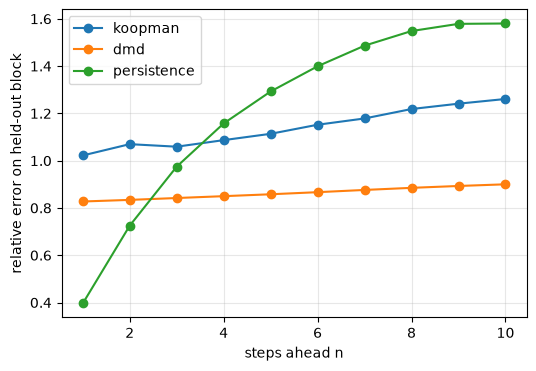

Result (Exercise 2): held-out contiguous block (190 starts): error at n=1 / n=10: Koopman 1.022 / 1.261, DMD 0.827 / 0.900, persistence 0.396 / 1.580


In [23]:
ex2_cut = int(0.8 * n_t)
ex2_Xa, ex2_ya = v[:ex2_cut - 1], v[1:ex2_cut]
ex2_Xt, ex2_Xv, ex2_yt, ex2_yv = train_test_split(ex2_Xa, ex2_ya, test_size=0.15, random_state=24, shuffle=True)
ex2_m, ex2_enc, ex2_op, ex2_dec = create_koopman_autoencoder(input_shape, latent_dim=latent_dim)
ex_fit_koopman(ex2_m, ex2_Xt, ex2_yt, ex2_Xv, ex2_yv)
ex2_P, ex2_A = ex_dmd(ex2_Xa, ex2_ya, latent_dim, v[:ex2_cut])
ex2_starts = np.arange(ex2_cut, n_t - 10)
z = ex2_enc.predict(v[ex2_starts], verbose=0); a = v[ex2_starts].reshape((len(ex2_starts), -1)) @ ex2_P
ex2_rows = []
for n in range(1, 11):
    z = ex2_op.predict(z, verbose=0); a = a @ ex2_A
    truth = v[ex2_starts + n]
    ex2_rows.append(dict(n_steps=n, koopman=relative_reconstruction_error(truth, ex2_dec.predict(z, verbose=0)).mean(),
                         dmd=relative_reconstruction_error(truth, (a @ ex2_P.T).reshape(truth.shape)).mean(),
                         persistence=relative_reconstruction_error(truth, v[ex2_starts]).mean()))
ex2 = pd.DataFrame(ex2_rows); ex2.to_csv(ex_dir / "ex2_contiguous_rollout.csv", index=False); print(ex2.round(4))
plt.figure(figsize=(6, 4))
for c in ("koopman", "dmd", "persistence"): plt.plot(ex2.n_steps, ex2[c], "o-", label=c)
plt.xlabel("steps ahead n"); plt.ylabel("relative error on held-out block"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(ex_dir / "ex2_contiguous_rollout.png", dpi=110); plt.show()
print(f"Result (Exercise 2): held-out contiguous block ({len(ex2_starts)} starts): error at n=1 / n=10: Koopman {ex2.koopman[0]:.3f} / {ex2.koopman[9]:.3f}, "
      f"DMD {ex2.dmd[0]:.3f} / {ex2.dmd[9]:.3f}, persistence {ex2.persistence[0]:.3f} / {ex2.persistence[9]:.3f}")

## Experiment 3 — solution
Eigenvalues of the classical DMD operator `A_dmd` (Section 9; since $b = a\,A_{\mathrm{DMD}}$, the eigenvalues are those of $A_{\mathrm{DMD}}^\top$, as for the learned operator) overlaid on those of the learned Koopman operator, with the unit circle. The table lists both sets sorted by modulus.

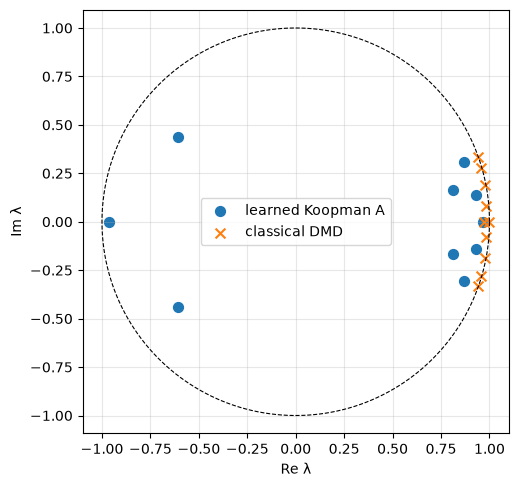

   koopman_abs  koopman_angle  dmd_abs  dmd_angle
0       0.9686         0.0000   0.9980     0.3392
1       0.9657         3.1416   0.9980     0.3392
2       0.9412         0.1494   0.9977     0.2822
3       0.9412         0.1494   0.9977     0.2822
4       0.9228         0.3398   0.9968     0.0000
5       0.9228         0.3398   0.9950     0.1907
6       0.8303         0.2016   0.9950     0.1907
7       0.8303         0.2016   0.9859     0.0824
8       0.7500         2.5185   0.9859     0.0824
9       0.7500         2.5185   0.9733     0.0000
Result (Exercise 3): largest |λ| learned 0.9686 (angle 0.000 rad) vs DMD 0.9980 (angle 0.339 rad); eigenvalues with |λ| > 0.99: learned 0, DMD 7


In [24]:
ex3_dmd_eig = np.linalg.eigvals(A_dmd.T)
theta = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(5.5, 5.5)); plt.plot(np.cos(theta), np.sin(theta), "k--", lw=0.8)
plt.scatter(eigenvalues.real, eigenvalues.imag, s=50, label="learned Koopman A"); plt.scatter(ex3_dmd_eig.real, ex3_dmd_eig.imag, s=50, marker="x", label="classical DMD")
plt.axis("equal"); plt.legend(); plt.grid(alpha=0.3); plt.xlabel("Re λ"); plt.ylabel("Im λ")
plt.savefig(ex_dir / "ex3_eigenvalues_overlay.png", dpi=110); plt.show()
ex3 = pd.DataFrame(dict(koopman_abs=np.sort(np.abs(eigenvalues))[::-1], koopman_angle=np.abs(np.angle(eigenvalues[np.argsort(-np.abs(eigenvalues))])),
                        dmd_abs=np.sort(np.abs(ex3_dmd_eig))[::-1], dmd_angle=np.abs(np.angle(ex3_dmd_eig[np.argsort(-np.abs(ex3_dmd_eig))]))))
ex3.to_csv(ex_dir / "ex3_eigenvalues.csv", index=False); print(ex3.round(4))
print(f"Result (Exercise 3): largest |λ| learned {ex3.koopman_abs[0]:.4f} (angle {ex3.koopman_angle[0]:.3f} rad) vs DMD {ex3.dmd_abs[0]:.4f} (angle {ex3.dmd_angle[0]:.3f} rad); "
      f"eigenvalues with |λ| > 0.99: learned {int((ex3.koopman_abs > 0.99).sum())}, DMD {int((ex3.dmd_abs > 0.99).sum())}")

## Experiment 4 — solution
Each eigenvector $w_j$ of $\mathbf{A}$ is complex, so its real part is used as a direction in latent space. It is scaled to the typical size of the latent codes, $\sigma_z$ (the RMS norm of the encoded data), and the decoded field $\psi(\sigma_z\,\mathrm{Re}\,w_j) - \psi(0)$ shows the spatial structure that direction adds. Modes are ordered by $|\lambda_j|$ and shown above the leading POD modes (columns of `Phi`).

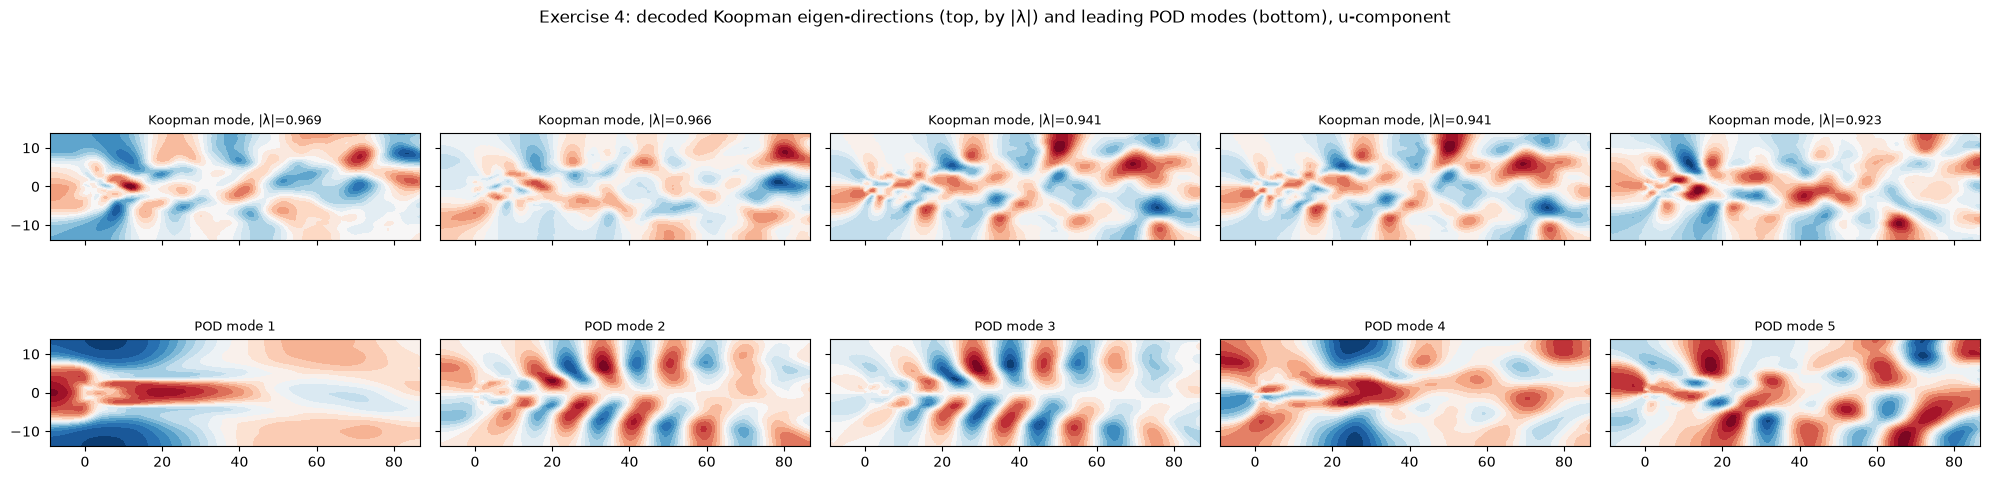

Result (Exercise 4): largest |cosine| between each decoded Koopman direction and the first 10 POD modes: 0.50, 0.43, 0.35, 0.35, 0.37


In [25]:
ex4_zall = koopman_encoder.predict(v, verbose=0); ex4_scale = np.sqrt(np.mean(np.sum(ex4_zall ** 2, axis=1)))
ex4_order = np.argsort(-np.abs(eigenvalues)); ex4_base = koopman_decoder.predict(np.zeros((1, latent_dim)), verbose=0)[0]
k = min(5, latent_dim); fig, axes = plt.subplots(2, k, figsize=(4 * k, 5.5), sharex=True, sharey=True); ex4_corr = []
for c in range(k):
    w = np.real(eigenvectors[:, ex4_order[c]]); w = w / (np.linalg.norm(w) + 1e-12) * ex4_scale
    f = koopman_decoder.predict(w[None].astype("float32"), verbose=0)[0] - ex4_base
    pod_c = Phi[:, c].reshape((n_x, n_y, n_v))
    axes[0, c].contourf(xx, yy, f[:, :, 0], levels=20, cmap="RdBu_r"); axes[0, c].set_title(f"Koopman mode, |λ|={abs(eigenvalues[ex4_order[c]]):.3f}", fontsize=9)
    axes[1, c].contourf(xx, yy, pod_c[:, :, 0], levels=20, cmap="RdBu_r"); axes[1, c].set_title(f"POD mode {c+1}", fontsize=9)
    for a_ in axes[:, c]: a_.set_aspect("equal")
    fl = f.ravel(); ex4_corr.append(float(np.max(np.abs(Phi[:, :10].T @ fl)) / (np.linalg.norm(fl) + 1e-12)))
fig.suptitle("Exercise 4: decoded Koopman eigen-directions (top, by |λ|) and leading POD modes (bottom), u-component"); fig.tight_layout()
plt.savefig(ex_dir / "ex4_koopman_modes.png", dpi=100); plt.show()
pd.DataFrame(dict(rank=range(1, k + 1), abs_lambda=np.abs(eigenvalues[ex4_order[:k]]), max_cos_with_first10_pod=ex4_corr)).to_csv(ex_dir / "ex4_modes.csv", index=False)
print("Result (Exercise 4): largest |cosine| between each decoded Koopman direction and the first 10 POD modes: " + ", ".join(f"{x:.2f}" for x in ex4_corr))

## Experiment 5 — solution
Koopman autoencoder and classical DMD, one-step prediction error on the notebook's validation pairs, for `latent_dim` in [2, 10, 50] (at most three configurations); the base `d = 10` model is reused for that entry.

   latent_dim  koopman     dmd     gap  epochs
0           2   0.9072  0.9067 -0.0005   150.0
1          10   0.5468  0.7211  0.1743     NaN
2          50   0.2469  0.3469  0.1001   150.0


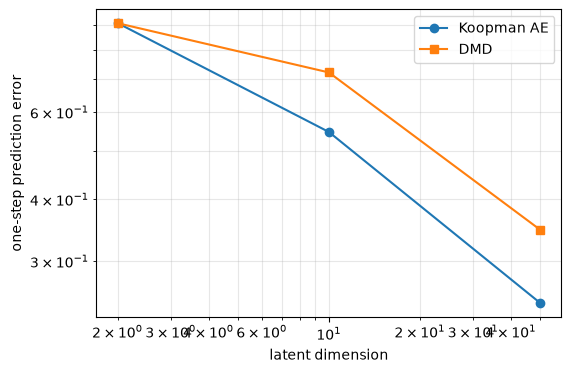

Result (Exercise 5): one-step error Koopman / DMD: d=2: 0.907 / 0.907; d=10: 0.547 / 0.721; d=50: 0.247 / 0.347


In [26]:
ex5_rows = []
for d in [2, 10, 50]:
    if d == latent_dim:
        kp = ex_koop_pred; ep = None
    else:
        m, *_ = create_koopman_autoencoder(input_shape, latent_dim=d); ep = ex_fit_koopman(m, X_trn, y_trn, X_val, y_val)
        kp = relative_reconstruction_error(y_val, m.predict(X_val, verbose=0)[1]).mean()
    P, A = ex_dmd(X_trn, y_trn, d, v)
    dm = relative_reconstruction_error(y_val, ((X_val.reshape((len(X_val), -1)) @ P) @ A @ P.T).reshape(y_val.shape)).mean()
    ex5_rows.append(dict(latent_dim=d, koopman=kp, dmd=dm, gap=dm - kp, epochs=ep))
ex5 = pd.DataFrame(ex5_rows); ex5.to_csv(ex_dir / "ex5_latent_sweep_prediction.csv", index=False); print(ex5.round(4))
plt.figure(figsize=(6, 4)); plt.semilogy(ex5.latent_dim, ex5.koopman, "o-", label="Koopman AE"); plt.semilogy(ex5.latent_dim, ex5.dmd, "s-", label="DMD")
plt.xscale("log"); plt.xlabel("latent dimension"); plt.ylabel("one-step prediction error"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.savefig(ex_dir / "ex5_latent_sweep_prediction.png", dpi=110); plt.show()
print("Result (Exercise 5): one-step error Koopman / DMD: " + "; ".join(f"d={r.latent_dim}: {r.koopman:.3f} / {r.dmd:.3f}" for r in ex5.itertuples()))

## Summary of the experiment solutions
- **Experiment 1:** linear versus non-linear latent operator.
- **Experiment 2:** a rollout evaluated on a contiguous held-out block with true future states.
- **Experiment 3:** learned versus DMD eigenvalues.
- **Experiment 4:** decoded Koopman directions next to POD modes.
- **Experiment 5:** Koopman versus DMD prediction error across latent sizes.

The numbers are those printed in the `Result` lines above.

# Animation — the Koopman autoencoder learning the dynamics
Built from the snapshots collected **during the base training** (hook cell before the training cell; no second training run): after every epoch, the losses, the one-step prediction of the last validation pair and the eigenvalues of the current operator $\mathbf{A}$. Dashboard: `../animations/03_training_dashboard.mp4`; last frame: `../animations/03_final_frame.png`.

In [27]:
import pickle
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = Path("../animations"); anim_dir.mkdir(exist_ok=True)
anim_y = y_val[-1]; pickle.dump(ANIM_CB.snaps, open(anim_dir / "03_snapshots.pkl", "wb"))

In [28]:
snaps = ANIM_CB.snaps; n_ep = snaps[-1]["epoch"]; tr = anim_y[:, :, 0]; vmin, vmax = tr.min(), tr.max()
H = np.array(snaps[-1]["hist"], dtype=float); th = np.linspace(0, 2 * np.pi, 200)
rmax = max(1.1, max(np.abs(s_["eig"]).max() for s_ in snaps) * 1.05)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
def anim_draw(k):
    s_ = snaps[k]
    for a in axes.ravel(): a.clear()
    axes[0, 0].contourf(xx, yy, tr, levels=30, cmap="RdBu_r", vmin=vmin, vmax=vmax); axes[0, 0].set_title("u(t+1), reference (validation pair)"); axes[0, 0].set_aspect("equal")
    axes[0, 1].contourf(xx, yy, s_["pred"][:, :, 0], levels=30, cmap="RdBu_r", vmin=vmin, vmax=vmax); axes[0, 1].set_title(f"u(t+1) = decode(A encode(u(t))), epoch {s_['epoch']}"); axes[0, 1].set_aspect("equal")
    axes[1, 0].plot(np.cos(th), np.sin(th), "k--", lw=0.8); axes[1, 0].scatter(s_["eig"].real, s_["eig"].imag, s=40, color="C3")
    axes[1, 0].set_xlim(-rmax, rmax); axes[1, 0].set_ylim(-rmax, rmax); axes[1, 0].set_aspect("equal"); axes[1, 0].set_title("Eigenvalues of the learned operator A"); axes[1, 0].grid(alpha=0.3)
    h = np.array(s_["hist"], dtype=float)
    if len(h):
        axes[1, 1].semilogy(h[:, 0], label="training total"); axes[1, 1].semilogy(h[:, 1], label="validation total")
    axes[1, 1].set_xlim(0, n_ep); axes[1, 1].set_ylim(np.nanmin(H[:, :2]) * 0.7, np.nanmax(H[:, :2]) * 1.5); axes[1, 1].legend(); axes[1, 1].set_xlabel("epoch"); axes[1, 1].grid(alpha=0.3, which="both"); axes[1, 1].set_title("Loss (reconstruction + one-step prediction)")
    fig.suptitle("Stage 3 — Koopman autoencoder, base run (seed 0)"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / "03_final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / "03_training_dashboard.mp4", writer=FFMpegWriter(fps=10, bitrate=1800), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

/var/folders/1h/r2mbj41x5f7d80jf6t_9hx_c0000gn/T/ipykernel_48320/1052054579.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1, 1].set_xlim(0, n_ep); axes[1, 1].set_ylim(np.nanmin(H[:, :2]) * 0.7, np.nanmax(H[:, :2]) * 1.5); axes[1, 1].legend(); axes[1, 1].set_xlabel("epoch"); axes[1, 1].grid(alpha=0.3, which="both"); axes[1, 1].set_title("Loss (reconstruction + one-step prediction)")


Animation: 218 frames written


**What the animation shows.** Top: the true velocity one step ahead for a validation pair, and the Koopman autoencoder's prediction (encode, apply the linear operator once, decode) after each epoch. Bottom left: the eigenvalues of the learned operator moving in the complex plane relative to the unit circle; as training proceeds they settle at or inside the circle, the leading ones close to it (persistent, oscillating latent directions of the periodic wake). Bottom right: training and validation loss.

# Three-seed repeats
Every training here takes well under 15 minutes, so each is repeated with the seeds 0, 1 and 2. **Seed 0 is the base run**: the notebook's Koopman autoencoder above (seeds set in the import cell) and the experiment solutions (`seed=0`). For seeds 1 and 2, `tf.keras.utils.set_random_seed(seed)` sets the initial weights and the batch order; data, split, settings and devices are unchanged. Persistence and DMD are deterministic. One cell per seed, then a summary of the one-step errors, the Experiment 2 rollout errors and the largest eigenvalue modulus.

In [29]:
# Three-seed repeats: helpers
def seed_koopman(d, Xt, yt, Xv, yv, seed, epochs):
    tf.keras.utils.set_random_seed(seed)
    m, enc, op, dec = create_koopman_autoencoder(input_shape, latent_dim=d)
    h = m.fit(Xt, [Xt, yt], validation_data=(Xv, [Xv, yv]), epochs=epochs, batch_size=32, verbose=0, callbacks=ex_cbs())
    return m, enc, op, dec, len(h.history["loss"])
def seed_run(seed):
    rows = []
    def add(part, config, val, epochs=None): rows.append(dict(seed=seed, part=part, config=config, value=float(val), epochs=epochs)); print(rows[-1], flush=True)
    m, enc, op, dec, ep = seed_koopman(latent_dim, X_trn, y_trn, X_val, y_val, seed, 600)
    rec, pred = m.predict(X_val, verbose=0)
    add("base", "Koopman AE one-step error", relative_reconstruction_error(y_val, pred).mean(), ep)
    add("base", "Koopman AE reconstruction error", relative_reconstruction_error(X_val, rec).mean(), ep)
    add("base", "max |eigenvalue| of A", np.abs(np.linalg.eigvals(op.get_layer("A").get_weights()[0].T)).max(), ep)
    with tf.device("/CPU:0"):
        tf.keras.utils.set_random_seed(seed)
        m1, *_ = ex_nonlinear_koopman(latent_dim); ep1 = ex_fit_koopman(m1, X_trn, y_trn, X_val, y_val, seed=seed)
        add("Exercise 1", "non-linear operator one-step error", relative_reconstruction_error(y_val, m1.predict(X_val, verbose=0)[1]).mean(), ep1)
    tf.keras.utils.set_random_seed(seed)
    m2, enc2, op2, dec2 = create_koopman_autoencoder(input_shape, latent_dim=latent_dim); ep2 = ex_fit_koopman(m2, ex2_Xt, ex2_yt, ex2_Xv, ex2_yv, seed=seed)
    z = enc2.predict(v[ex2_starts], verbose=0)
    for n in range(1, 11):
        z = op2.predict(z, verbose=0)
        if n in (1, 5, 10): add("Exercise 2 (contiguous rollout)", f"Koopman n={n}", relative_reconstruction_error(v[ex2_starts + n], dec2.predict(z, verbose=0)).mean(), ep2)
    for d in (2, 50):
        tf.keras.utils.set_random_seed(seed)
        md, *_ = create_koopman_autoencoder(input_shape, latent_dim=d); epd = ex_fit_koopman(md, X_trn, y_trn, X_val, y_val, seed=seed)
        add("Exercise 5", f"Koopman one-step d={d}", relative_reconstruction_error(y_val, md.predict(X_val, verbose=0)[1]).mean(), epd)
    return rows
seed_rows = [dict(seed=0, part="base", config="Koopman AE one-step error", value=float(koopman_pred_error.mean()), epochs=len(history_koopman.history["loss"])),
             dict(seed=0, part="base", config="Koopman AE reconstruction error", value=float(koopman_rec_error.mean()), epochs=len(history_koopman.history["loss"])),
             dict(seed=0, part="base", config="max |eigenvalue| of A", value=float(np.abs(eigenvalues).max())),
             dict(seed=0, part="Exercise 1", config="non-linear operator one-step error", value=float(ex1.one_step_error[1]), epochs=ex1_ep)]
seed_rows += [dict(seed=0, part="Exercise 2 (contiguous rollout)", config=f"Koopman n={n}", value=float(ex2.koopman[n - 1])) for n in (1, 5, 10)]
seed_rows += [dict(seed=0, part="Exercise 5", config=f"Koopman one-step d={r.latent_dim}", value=float(r.koopman), epochs=r.epochs) for r in ex5.itertuples() if r.latent_dim != latent_dim]
print(len(seed_rows), "base-run (seed 0) rows")

9 base-run (seed 0) rows


In [30]:
# Seed 1
seed_rows += seed_run(1)

{'seed': 1, 'part': 'base', 'config': 'Koopman AE one-step error', 'value': 0.512912240228083, 'epochs': 204}


{'seed': 1, 'part': 'base', 'config': 'Koopman AE reconstruction error', 'value': 0.5050434010427928, 'epochs': 204}


{'seed': 1, 'part': 'base', 'config': 'max |eigenvalue| of A', 'value': 0.9942229390144348, 'epochs': 204}


{'seed': 1, 'part': 'Exercise 1', 'config': 'non-linear operator one-step error', 'value': 0.5987041194382452, 'epochs': 150}


{'seed': 1, 'part': 'Exercise 2 (contiguous rollout)', 'config': 'Koopman n=1', 'value': 1.010988802021266, 'epochs': 150}


{'seed': 1, 'part': 'Exercise 2 (contiguous rollout)', 'config': 'Koopman n=5', 'value': 1.3856909352111848, 'epochs': 150}


{'seed': 1, 'part': 'Exercise 2 (contiguous rollout)', 'config': 'Koopman n=10', 'value': 2.215934349325352, 'epochs': 150}


{'seed': 1, 'part': 'Exercise 5', 'config': 'Koopman one-step d=2', 'value': 0.8824635191523125, 'epochs': 105}


{'seed': 1, 'part': 'Exercise 5', 'config': 'Koopman one-step d=50', 'value': 0.24442184079711696, 'epochs': 150}


In [31]:
# Seed 2
seed_rows += seed_run(2)

{'seed': 2, 'part': 'base', 'config': 'Koopman AE one-step error', 'value': 0.533679684461356, 'epochs': 178}


{'seed': 2, 'part': 'base', 'config': 'Koopman AE reconstruction error', 'value': 0.5323844471787411, 'epochs': 178}


{'seed': 2, 'part': 'base', 'config': 'max |eigenvalue| of A', 'value': 1.069183588027954, 'epochs': 178}


{'seed': 2, 'part': 'Exercise 1', 'config': 'non-linear operator one-step error', 'value': 0.6252048088365942, 'epochs': 150}


{'seed': 2, 'part': 'Exercise 2 (contiguous rollout)', 'config': 'Koopman n=1', 'value': 1.0187196090909856, 'epochs': 150}


{'seed': 2, 'part': 'Exercise 2 (contiguous rollout)', 'config': 'Koopman n=5', 'value': 1.1166829608237907, 'epochs': 150}


{'seed': 2, 'part': 'Exercise 2 (contiguous rollout)', 'config': 'Koopman n=10', 'value': 1.1586949655693146, 'epochs': 150}


{'seed': 2, 'part': 'Exercise 5', 'config': 'Koopman one-step d=2', 'value': 0.8695153448222664, 'epochs': 150}


{'seed': 2, 'part': 'Exercise 5', 'config': 'Koopman one-step d=50', 'value': 0.24510025391019666, 'epochs': 150}


In [32]:
# Three-seed summary
seed_runs = pd.DataFrame(seed_rows); seed_runs.to_csv(ex_dir / "seeds_runs.csv", index=False)
seed_sum = seed_runs.groupby(["part", "config"], sort=False).value.agg(["mean", "std", "min", "max", "count"]).reset_index()
seed_sum.to_csv(ex_dir / "seeds_summary.csv", index=False)
print(seed_sum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nDeterministic references, one-step: persistence {persistence_error.mean():.4f}, DMD rank {latent_dim} {dmd_error.mean():.4f}; "
      f"contiguous rollout n=1/5/10: DMD {ex2.dmd[0]:.4f}/{ex2.dmd[4]:.4f}/{ex2.dmd[9]:.4f}, persistence {ex2.persistence[0]:.4f}/{ex2.persistence[4]:.4f}/{ex2.persistence[9]:.4f}")

                           part                             config   mean    std    min    max  count
                           base          Koopman AE one-step error 0.5311 0.0171 0.5129 0.5468      3
                           base    Koopman AE reconstruction error 0.5246 0.0171 0.5050 0.5365      3
                           base              max |eigenvalue| of A 1.0107 0.0523 0.9686 1.0692      3
                     Exercise 1 non-linear operator one-step error 0.6048 0.0182 0.5905 0.6252      3
Exercise 2 (contiguous rollout)                        Koopman n=1 1.0173 0.0057 1.0110 1.0221      3
Exercise 2 (contiguous rollout)                        Koopman n=5 1.2053 0.1562 1.1136 1.3857      3
Exercise 2 (contiguous rollout)                       Koopman n=10 1.5452 0.5831 1.1587 2.2159      3
                     Exercise 5               Koopman one-step d=2 0.8864 0.0191 0.8695 0.9072      3
                     Exercise 5              Koopman one-step d=50 0.2455 0.0013 0